In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cleaned_data.csv", parse_dates=["Transaction Date"])
print(df.shape)
df.head()

(9942, 8)


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,4.0,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,Unknown,Unknown,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [3]:
df[["Quantity", "Price Per Unit", "Total Spent"]].describe()

,Quantity,Price Per Unit,Total Spent
count,9942.000000,9942.000000,9942.000000
mean,3.025749,2.947848,8.931855
std,1.420438,1.279897,6.002356
min,1.000000,1.000000,1.000000
25%,2.000000,2.000000,4.000000
50%,3.000000,3.000000,8.000000
75%,4.000000,4.000000,12.000000
max,5.000000,5.000000,25.000000


In [4]:
print("Total transactions:", len(df))
print("Total revenue:", df["Total Spent"].sum())
print("Average spend per transaction:", round(df["Total Spent"].mean(), 2))
print("Total items sold:", df["Quantity"].sum())

Total transactions: 9942
Total revenue: 88800.5
Average spend per transaction: 8.93
Total items sold: 30082


In [5]:
item_stats = df.groupby("Item").agg(
    revenue=("Total Spent", "sum"),
    items_sold=("Quantity", "sum"),
    transactions=("Transaction ID", "count")
).sort_values("revenue", ascending=False)
item_stats

,revenue,items_sold,transactions
Item,,,
Salad,17315.0,3463,1144
Sandwich,13644.0,3411,1122
Smoothie,13296.0,3324,1089
Juice,10509.0,3503,1167
Cake,10377.0,3459,1134
Unknown,8453.5,2888,963
Coffee,7058.0,3529,1158
Tea,4929.0,3286,1081
Cookie,3219.0,3219,1084


In [6]:
print(df["Payment Method"].value_counts())
print("-----")
print(df["Location"].value_counts())
print("-----")
print(df.groupby("Location")["Total Spent"].mean().round(2))

Payment Method
Unknown           3158
Digital Wallet    2280
Credit Card       2260
Cash              2244
Name: count, dtype: int64
-----
Location
Unknown     3940
Takeaway    3004
In-store    2998
Name: count, dtype: int64
-----
Location
In-store    9.03
Takeaway    8.80
Unknown     8.95
Name: Total Spent, dtype: float64


In [7]:
df["Month"] = df["Transaction Date"].dt.month
monthly = df.groupby("Month")["Total Spent"].sum()
monthly

Month
1.0     7219.0
2.0     6626.0
3.0     7190.5
4.0     7168.0
5.0     6916.5
6.0     7350.0
7.0     6876.5
8.0     7049.5
9.0     6842.0
10.0    7295.0
11.0    6957.0
12.0    7153.0
Name: Total Spent, dtype: float64

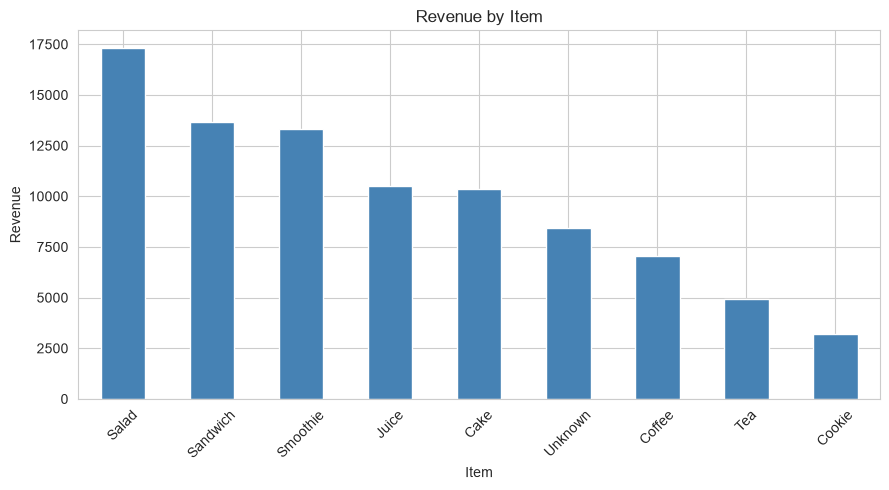

In [8]:
sns.set_style("whitegrid")

rev = df.groupby("Item")["Total Spent"].sum().sort_values(ascending=False)
plt.figure(figsize=(9, 5))
rev.plot(kind="bar", color="steelblue")
plt.title("Revenue by Item")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("chart1_revenue_by_item.png", dpi=150)
plt.show()

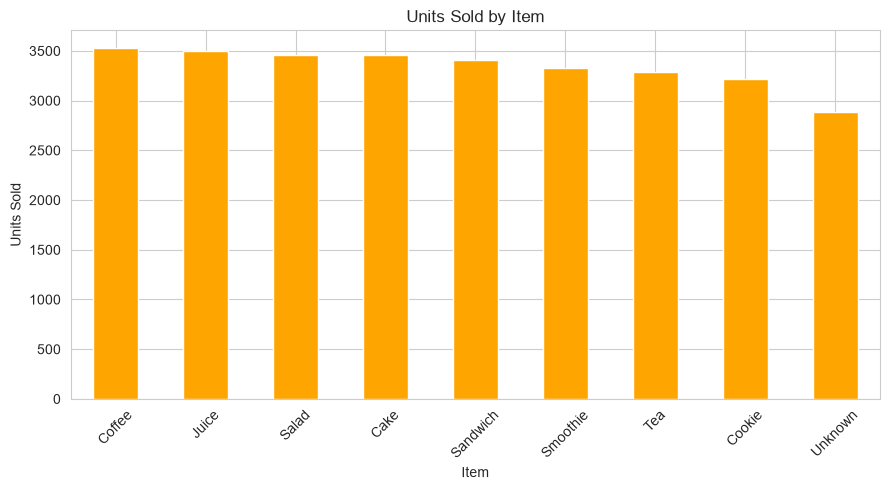

In [9]:
units = df.groupby("Item")["Quantity"].sum().sort_values(ascending=False)
plt.figure(figsize=(9, 5))
units.plot(kind="bar", color="orange")
plt.title("Units Sold by Item")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("chart2_units_by_item.png", dpi=150)
plt.show()

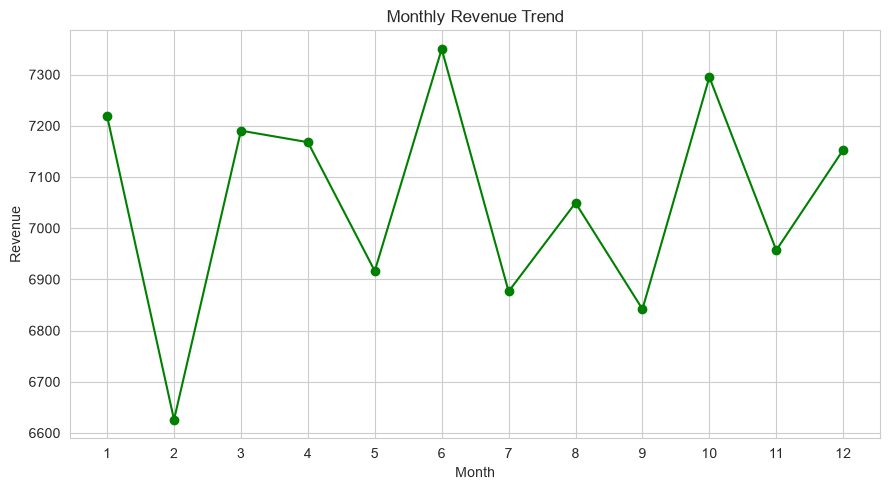

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(monthly.index.astype(int), monthly.values, marker="o", color="green")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.savefig("chart3_monthly_revenue.png", dpi=150)
plt.show()

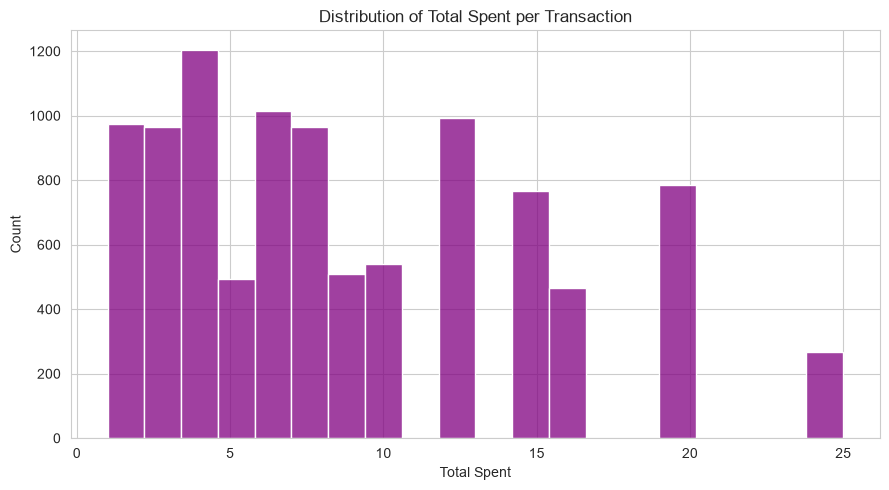

In [11]:
plt.figure(figsize=(9, 5))
sns.histplot(df["Total Spent"], bins=20, color="purple")
plt.title("Distribution of Total Spent per Transaction")
plt.xlabel("Total Spent")
plt.tight_layout()
plt.savefig("chart4_spend_distribution.png", dpi=150)
plt.show()

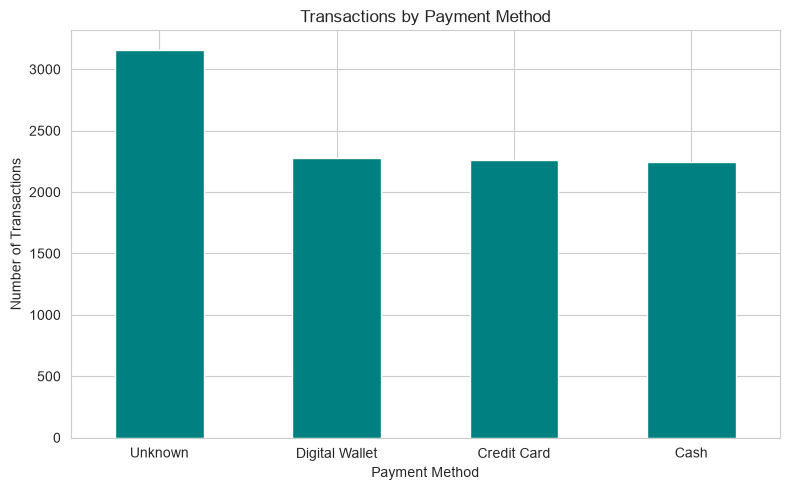

In [12]:
pay = df["Payment Method"].value_counts()
plt.figure(figsize=(8, 5))
pay.plot(kind="bar", color="teal")
plt.title("Transactions by Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("chart5_payment_methods.png", dpi=150)
plt.show()

In [13]:
print("=== ITEM STATS (full) ===")
print(item_stats)

print("\n=== PAYMENT METHOD ===")
print(df["Payment Method"].value_counts())

print("\n=== LOCATION ===")
print(df["Location"].value_counts())
print(df.groupby("Location")["Total Spent"].mean().round(2))

print("\n=== ANOMALY CHECK ===")
df["Calc Total"] = df["Quantity"] * df["Price Per Unit"]
print("Rows where Total != Quantity x Price:", (df["Total Spent"] != df["Calc Total"]).sum())
print("Rows with missing date:", df["Transaction Date"].isnull().sum())
print("Highest single order:", df["Total Spent"].max())
print("Orders at the maximum:", (df["Total Spent"] == df["Total Spent"].max()).sum())

=== ITEM STATS (full) ===
          revenue  items_sold  transactions
Item                                       
Salad     17315.0        3463          1144
Sandwich  13644.0        3411          1122
Smoothie  13296.0        3324          1089
Juice     10509.0        3503          1167
Cake      10377.0        3459          1134
Unknown    8453.5        2888           963
Coffee     7058.0        3529          1158
Tea        4929.0        3286          1081
Cookie     3219.0        3219          1084

=== PAYMENT METHOD ===
Payment Method
Unknown           3158
Digital Wallet    2280
Credit Card       2260
Cash              2244
Name: count, dtype: int64

=== LOCATION ===
Location
Unknown     3940
Takeaway    3004
In-store    2998
Name: count, dtype: int64
Location
In-store    9.03
Takeaway    8.80
Unknown     8.95
Name: Total Spent, dtype: float64

=== ANOMALY CHECK ===
Rows where Total != Quantity x Price: 0
Rows with missing date: 457
Highest single order: 25.0
Orders at the max

# Key Insights

## Insight 1: Salad is the top revenue driver
Salad earns 17,315, about 19.5% of total revenue (88,800.5), and the top 3 items (Salad, Sandwich, Smoothie) together earn about 50% of it. (Chart 1)

## Insight 2: Popularity does not equal revenue
Units sold are almost equal across items (3,219 to 3,529). Coffee sells the most units (3,529) but earns only 7,058 because it costs 2 per item. Salad sold only 7.6% more units than Cookie (3,463 vs 3,219) but earned about 5.4 times more revenue (17,315 vs 3,219) because it costs 5 vs 1. Price per unit decides revenue. (Charts 1 and 2)

## Insight 3: Sales are stable all year with no strong seasonality
Monthly revenue stays between 6,626 (February, the lowest) and 7,350 (June, the highest), a spread of about 11%. Demand is steady, so there is no seasonal peak to plan around. (Chart 3)

## Insight 4: Customers spend about 8 to 9 per visit, and 2.7% of orders hit the maximum
The average transaction is 8.93 and the median is 8. The maximum is 25 (5 units of the 5-price item), which is a valid order, not an error, and 267 orders (2.7%) reach it. The few large orders pull the average slightly above the median. (Chart 4)

## Insight 5: Customers split evenly across payment methods and locations
Among known values, Digital Wallet (2,280), Credit Card (2,260) and Cash (2,244) are each about one-third of transactions. Takeaway (3,004) and In-store (2,998) are also nearly equal. In-store orders average a little more (9.03 vs 8.80, about 2.6% higher). (Chart 5)

## Data quality notes
- 0 rows have a Total that disagrees with Quantity × Price, so the cleaned data is consistent.
- "Unknown" is a large group: Item (963 transactions, 9.5% of revenue), Payment Method (3,158) and Location (3,940). These values could not be recovered, so payment and location insights are based on known values only.
- 457 rows have no date, so monthly totals exclude them.